In [ ]:
# Import odpowiednich bibliotek

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import missingno as msno


df = pd.read_excel('../data/raw/2023_PM10_1g.xlsx')

Dane pochodzą ze stacji pomiarowych funkcjonujących w ramach Państwowego Monitoringu Środowiska. Dane przedstawiają zawartość w powietrzu [ug/m^3] PM10 – mieszanina zawieszonych w powietrzu cząsteczek o średnicy nie większej niż 10 μm. W skład mogą wchodzić takie substancje toksyczne jak np. benzopireny, dioksyny i furany. Występowanie pyłów PM10 związane jest m.in. z procesami spalania paliw stałych i ciekłych

In [29]:
# Prezentacja danych

df

,DateTime,DsCzerStraza,DsDziePilsud,DsJelGorOgin,DsKlodzSzkol,DsLegAlRzecz,DsLwowekSlasMOB,DsNowRudJezi,DsOlawZolnAK,DsPolanZdrojMOB,...,WpKozieosLes,WpMosinaCzer,WpPleszAlMic,WpPoznDabrow,WpPoznSzwajc,ZpKoszArKraj,ZpSwinMatejkMOB,ZpSzczAndrze,ZpSzczecPrze,ZpSzczPilsud
0,2023-01-01 01:00:00,NaN,11.77200,13.37850,14.45620,76.73140,17.03740,49.19000,18.68970,NaN,...,37.1752,29.4463,12.4827,29.70770,9.87387,NaN,29.6184,84.1915,21.24280,35.8162
1,2023-01-01 02:00:00,NaN,8.03955,7.49011,8.18981,12.18880,8.02517,44.17970,12.06860,NaN,...,40.8653,39.6937,22.0795,8.76267,14.97750,NaN,11.6780,67.5318,37.94630,12.2973
2,2023-01-01 03:00:00,NaN,4.86186,7.17300,6.12140,7.71013,7.47221,20.10860,6.46206,NaN,...,26.3092,28.4824,15.5169,7.62683,8.45770,NaN,12.4690,20.9143,9.17905,14.6285
3,2023-01-01 04:00:00,NaN,3.78430,7.52949,4.45085,5.30297,8.16267,1.23622,12.95950,NaN,...,13.9113,20.0596,12.8348,7.65438,7.40454,NaN,14.7670,20.1431,9.54783,16.9437
4,2023-01-01 05:00:00,NaN,6.75353,12.80490,6.67913,10.25240,11.21650,7.65939,13.32400,NaN,...,10.1572,15.0812,11.4027,8.29311,8.40526,NaN,17.9912,23.2103,15.05800,15.8235
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,2023-12-31 20:00:00,8.67071,9.49446,15.52520,11.67630,59.18580,61.89870,329.18000,40.86630,47.1323,...,31.4129,33.3144,46.7624,14.76190,33.20080,19.7210,NaN,26.1971,21.20020,20.5803
8756,2023-12-31 21:00:00,8.72762,11.54030,15.17870,12.78180,92.77830,49.25850,264.23800,14.27490,67.1554,...,33.1705,36.7139,43.8902,15.25460,34.82190,21.8262,NaN,30.1043,23.12630,23.6297
8757,2023-12-31 22:00:00,5.77080,11.45540,17.46750,24.85880,54.78350,84.01440,226.70500,25.79380,61.5450,...,36.1229,41.3658,48.5587,15.79550,36.05560,22.2266,NaN,29.0216,23.80170,24.7189
8758,2023-12-31 23:00:00,6.24542,8.45763,26.18840,44.12650,75.28520,89.21640,196.26200,33.74250,71.9498,...,38.9877,46.6947,46.6115,16.63970,39.16020,25.0797,NaN,28.4944,29.41760,23.9728


In [30]:
# Filtracja do 10 kolumn z najwieksza iloscia brakujacych danych

top_10_missing_columns_sorted = df.isnull().sum().sort_values(ascending=False).head(10)
print("Top 10 Columns with Most Missing Values (Descending):")
print(top_10_missing_columns_sorted)

filtered_df = df[['DateTime'] + list(top_10_missing_columns_sorted.index)]


Top 10 Columns with Most Missing Values (Descending):
WpPoznDabrow       2556
LdPioTrKraPr       1430
LdLodzGdansk       1422
LdPabiKonsta       1420
MpKrakOsPias       1345
PmSlupKniazi       1199
SkKielJurajs       1187
WpKoscianMayMOB    1121
WmOstrPilsud       1037
PdBialAlPils        998
dtype: int64


In [32]:
filtered_df.iloc[:, 0] = pd.to_datetime(filtered_df.iloc[:, 0])
datetimecol = filtered_df.iloc[:, 0]
filtered_df.set_index(filtered_df.columns[0], inplace=True)
filtered_df

C:\Users\Jakub\AppData\Local\Temp\ipykernel_18080\396782915.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df.iloc[:, 0] = pd.to_datetime(filtered_df.iloc[:, 0])
C:\Users\Jakub\AppData\Local\Temp\ipykernel_18080\396782915.py:1: DeprecationWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  filtered_df.iloc[:, 0] = pd.to_datetime(filtered_df.iloc[:, 0])


,WpPoznDabrow,LdPioTrKraPr,LdLodzGdansk,LdPabiKonsta,MpKrakOsPias,PmSlupKniazi,SkKielJurajs,WpKoscianMayMOB,WmOstrPilsud,PdBialAlPils
DateTime,,,,,,,,,,
2023-01-01 01:00:00,29.70770,33.630,61.0134,27.8720,263.9650,11.0000,15.3,NaN,25.0195,NaN
2023-01-01 02:00:00,8.76267,21.090,42.6258,17.8720,154.5990,11.2466,45.6,NaN,11.0414,11.9350
2023-01-01 03:00:00,7.62683,18.924,8.2187,13.8720,54.7269,13.2020,41.1,NaN,13.0984,9.9018
2023-01-01 04:00:00,7.65438,17.898,6.8257,8.8720,40.8342,13.6077,29.6,NaN,13.2797,10.4998
2023-01-01 05:00:00,8.29311,12.654,NaN,10.8720,44.7827,14.7940,22.1,NaN,14.2086,12.1742
...,...,...,...,...,...,...,...,...,...,...
2023-12-31 20:00:00,14.76190,NaN,11.0047,25.3667,24.1855,12.0132,29.4,52.6577,27.9904,34.0000
2023-12-31 21:00:00,15.25460,NaN,15.1837,26.3097,37.9393,23.9849,29.8,67.8074,36.1303,31.9000
2023-12-31 22:00:00,15.79550,NaN,34.8250,32.9107,31.8240,14.2802,30.3,64.0395,28.4964,21.9000


In [33]:
datetimecol

0      2023-01-01 01:00:00
1      2023-01-01 02:00:00
2      2023-01-01 03:00:00
3      2023-01-01 04:00:00
4      2023-01-01 05:00:00
               ...        
8755   2023-12-31 20:00:00
8756   2023-12-31 21:00:00
8757   2023-12-31 22:00:00
8758   2023-12-31 23:00:00
8759   2024-01-01 00:00:00
Name: DateTime, Length: 8760, dtype: datetime64[ns]

In [22]:

import pandas as pd
from bokeh.plotting import figure, output_file, show, ColumnDataSource, reset_output
from bokeh.io import show
from bokeh.layouts import column, row
from bokeh.models import Select, CustomJS, Slider, PreText, CheckboxGroup


In [34]:
# Utworzenie wykresu z porownaniem danych dla 3 stacji wybierancyh z rozwijanej listy

TITLE = 'DataVisualizationPerStation'
output_file(TITLE+'.html')
source = ColumnDataSource(filtered_df)

p = figure(width=1500, height=800, x_axis_type='datetime', y_axis_label="[ug/m^3] PM10")

p.toolbar.logo = "grey"
p.background_fill_color = "#dddddd"
p.xaxis.axis_label = "DateTime"
p.grid.grid_line_color = "white"

p.line(x = "DateTime", y = "WpPoznDabrow", source = source, legend_label = "Stacja 1", color = "red" )
p.line(x = "DateTime", y = "LdPioTrKraPr", source = source, legend_label = "Stacja 2", color = "blue" )
p.line(x = "DateTime", y = "LdLodzGdansk", source = source, legend_label = "Stacja 3", color = "green" )

ys = Select(title= "Stacja 1", value = 'WpPoznDabrow', options = filtered_df.columns.tolist()[1:])
zs = Select(title= "Stacja 2", value = 'LdPioTrKraPr', options = filtered_df.columns.tolist()[1:])
ws = Select(title= "Stacja 3", value = 'LdLodzGdansk', options = filtered_df.columns.tolist()[1:])


callback1 = CustomJS(args=dict(source=source, sel1=ys), code=""" 
                     source.data['WpPoznDabrow'] = source.data[sel1.value];
                     
                     source.change.emit();
                     sel1.change.emit();
""")

callback2 = CustomJS(args=dict(source=source, sel2=zs), code=""" 
                     source.data['LdPioTrKraPr'] = source.data[sel2.value];
                     
                     source.change.emit();
                     sel2.change.emit();
""")

callback3 = CustomJS(args=dict(source=source, sel3=ws), code=""" 
                     source.data['LdLodzGdansk'] = source.data[sel3.value];
                     
                     source.change.emit();
                     sel3.change.emit();
""")

ys.js_on_change('value', callback1)
zs.js_on_change('value', callback2)
ws.js_on_change('value', callback3)
controls = column(ys, zs, ws )
layout = row(controls, p)

p.legend.click_policy='hide'

show(layout)

In [35]:
import pandas as pd
import numpy as np
from sklearn.experimental import enable_iterative_imputer  # Enable IterativeImputer
from sklearn.impute import IterativeImputer

imputer = IterativeImputer(max_iter=10, random_state=42)

# Fit and transform the data
imputed_data = imputer.fit_transform(filtered_df)

# Convert back to DataFrame
df_imputed = pd.DataFrame(imputed_data, columns=filtered_df.columns)
df_imputed["DateTime"] = datetimecol

In [36]:
# Utworzenie wykresu z porownaniem danych dla 3 stacji wybierancyh z rozwijanej listy

TITLE = 'DataVisualization'
output_file(TITLE+'.html')
source = ColumnDataSource(df_imputed)

p = figure(width=1500, height=800, x_axis_type='datetime', y_axis_label="[ug/m^3] PM10")

p.toolbar.logo = "grey"
p.background_fill_color = "#dddddd"
p.xaxis.axis_label = "DateTime"
p.grid.grid_line_color = "white"

p.line(x = "DateTime", y = "WpPoznDabrow", source = source, legend_label = "Stacja 1", color = "red" )
p.line(x = "DateTime", y = "LdPioTrKraPr", source = source, legend_label = "Stacja 2", color = "blue" )
p.line(x = "DateTime", y = "LdLodzGdansk", source = source, legend_label = "Stacja 3", color = "green" )

ys = Select(title= "Stacja 1", value = 'WpPoznDabrow', options = df_imputed.columns.tolist()[1:])
zs = Select(title= "Stacja 2", value = 'LdPioTrKraPr', options = df_imputed.columns.tolist()[1:])
ws = Select(title= "Stacja 3", value = 'LdLodzGdansk', options = df_imputed.columns.tolist()[1:])


callback1 = CustomJS(args=dict(source=source, sel1=ys), code=""" 
                     source.data['WpPoznDabrow'] = source.data[sel1.value];
                     
                     source.change.emit();
                     sel1.change.emit();
""")

callback2 = CustomJS(args=dict(source=source, sel2=zs), code=""" 
                     source.data['LdPioTrKraPr'] = source.data[sel2.value];
                     
                     source.change.emit();
                     sel2.change.emit();
""")

callback3 = CustomJS(args=dict(source=source, sel3=ws), code=""" 
                     source.data['LdLodzGdansk'] = source.data[sel3.value];
                     
                     source.change.emit();
                     sel3.change.emit();
""")

ys.js_on_change('value', callback1)
zs.js_on_change('value', callback2)
ws.js_on_change('value', callback3)
controls = column(ys, zs, ws )
layout = row(controls, p)

p.legend.click_policy='hide'

show(layout)

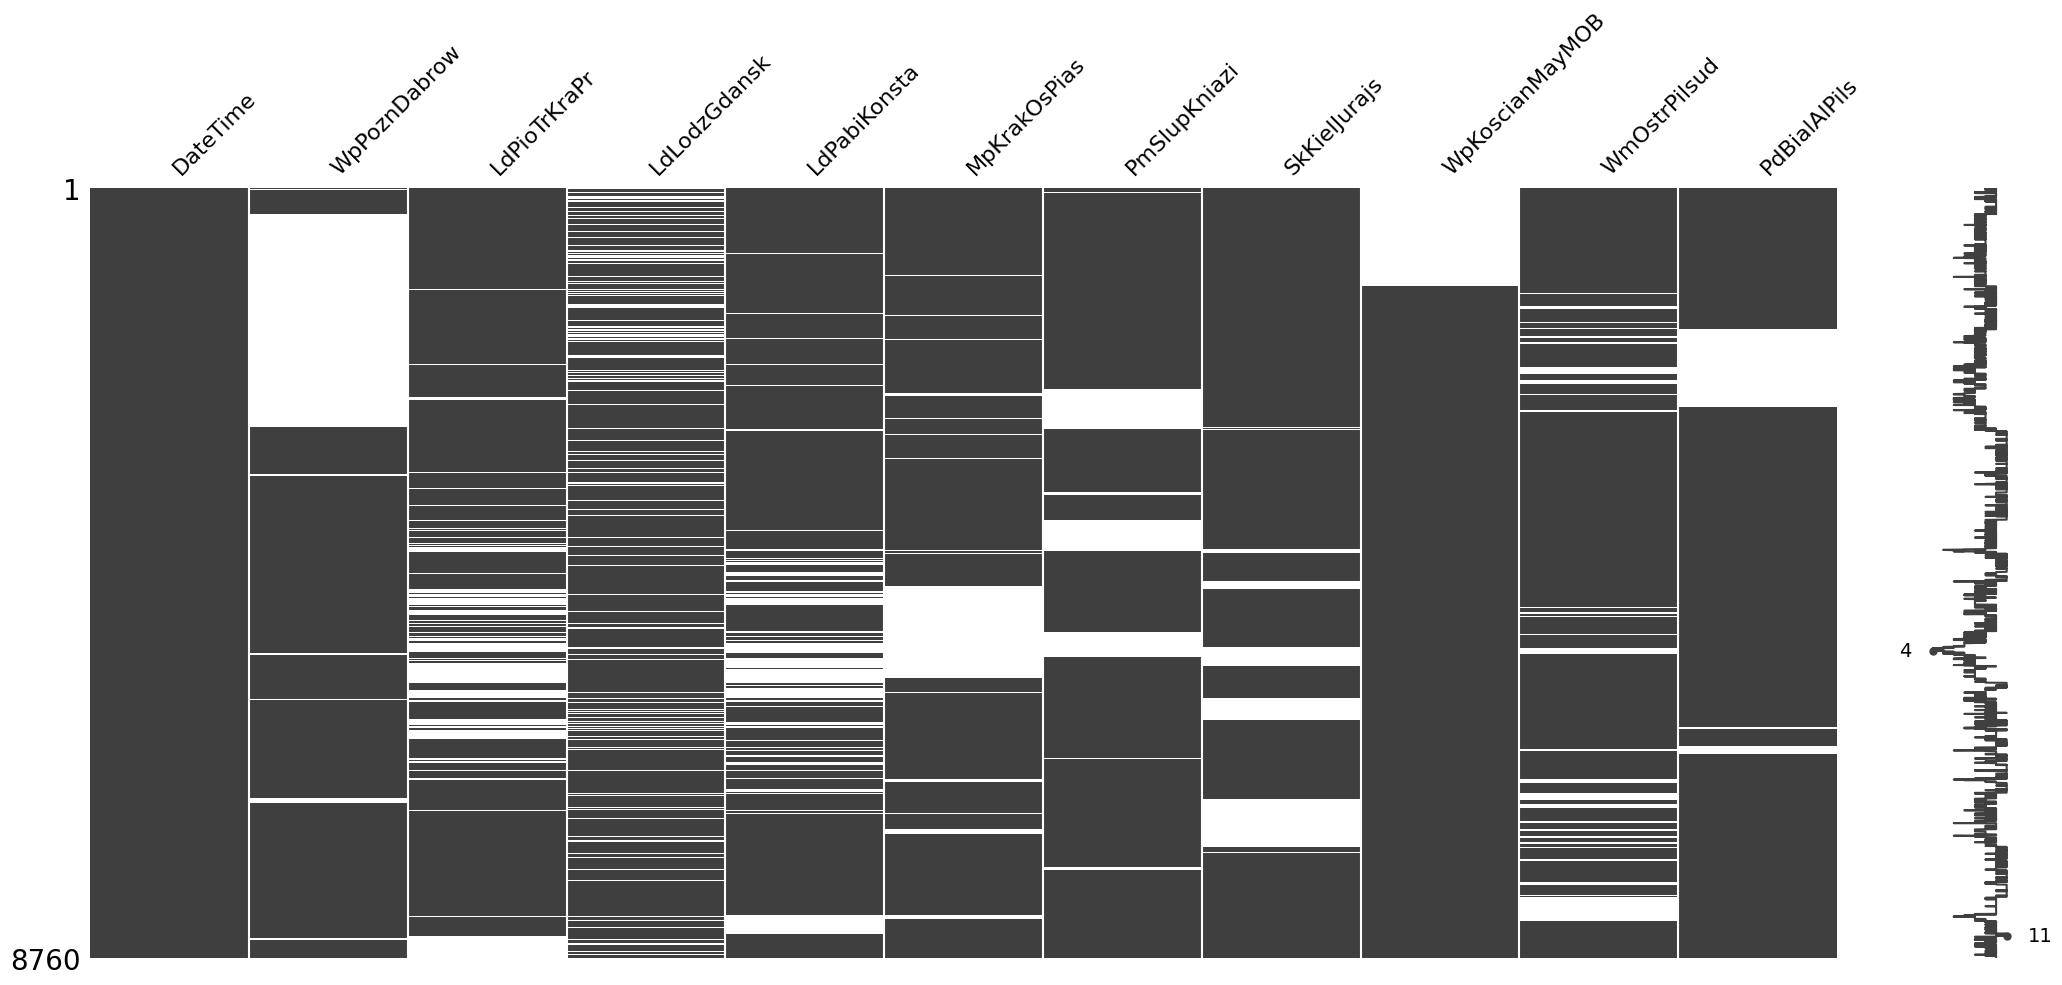

In [5]:
# Prezentacja brakow danych

msno.matrix(filtered_df) 
plt.savefig("missing_data_matrix.png", dpi=300, bbox_inches='tight') 

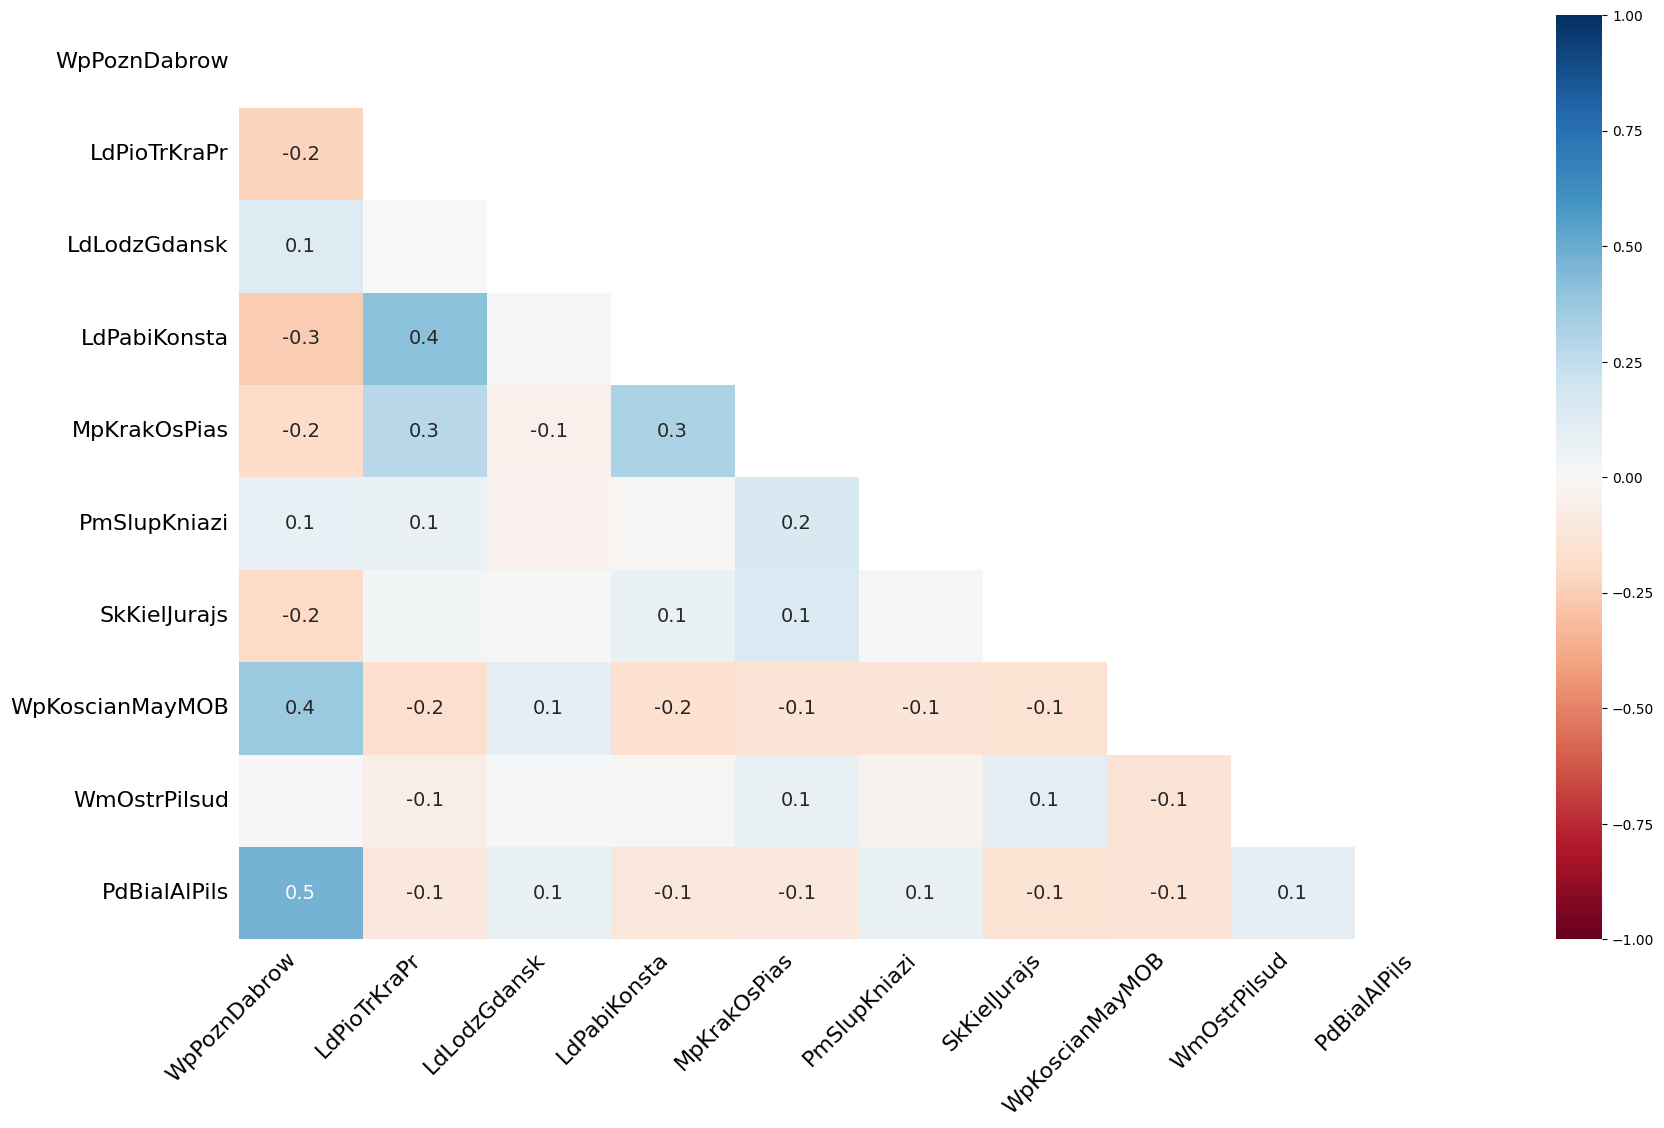

In [6]:
# Sprawdzenie korelacji w brakach danych

msno.heatmap(filtered_df)
plt.savefig("missing_data_heatmap.png", dpi=300, bbox_inches='tight') 

In [9]:
# Wykres prezentujący braki danych w czasie z dodatkowa informacja oznaczona kolorem na temat ostatniej awarii 

import plotly.express as px
missing_data = filtered_df.set_index('DateTime').isnull()
missing_timeline = missing_data.stack().reset_index()
missing_timeline.columns = ['DateTime', 'Column', 'IsMissing']
missing_timeline = missing_timeline[missing_timeline['IsMissing']]

missing_timeline['Duration'] = missing_timeline.groupby('Column')['DateTime'].diff().dt.days.fillna(0).abs()
missing_timeline['ColorCategory'] = pd.cut(
    missing_timeline['Duration'],
    bins = [-1, 0, 24, 168, 730, float('inf')], 
    labels=['1 hour+', '1 day+', '1 week+', '1 month', '1 month+'],
    include_lowest=True
)

fig = px.scatter(
    missing_timeline,
    x='DateTime',
    y='Column',
    title='Top 10 Stations With Missing Data With Indicator of Last Malfunction',
    labels={'DateTime': 'DateTime', 'Column': 'Stations Identifiers', 'ColorCategory': 'Time from Last Malfunction'},
    color='ColorCategory',
    color_discrete_map={'1 hour+': 'red', '1 day+': 'blue', '1 week+': 'green', '1 month+': 'brown'},
    height=600
)

fig.update_traces(marker=dict(size=6, opacity=0.8))
fig.show()
fig.write_html("missing_data_plot.html")

In [75]:
# Wykres prezentujący braki danych w czasie z dodatkowa informacja oznaczona kolorem na temat ile stacji uległo awarii w tym samym momenie


missing_counts = missing_timeline.groupby('DateTime').size().reset_index(name='MissingCount')

missing_timeline = pd.merge(missing_timeline, missing_counts, on='DateTime')

def assign_color(row):
    if row['MissingCount'] > 4:
        return '5-10'
    elif row['MissingCount'] > 1:
        return '2-4'
    else:
        return '1'

missing_timeline['ColorCategory'] = missing_timeline.apply(assign_color, axis=1)

fig = px.scatter(
    missing_timeline,
    x='DateTime',
    y='Column',
    title='Top 10 Stations With Missing Data With Indication of How Many Stations Have Failures Simultaneously',
    labels={'DateTime': 'DateTime', 'Column': 'Stations Identifiers', 'ColorCategory': 'Malfunctioning Stations'},
    color='ColorCategory',
    color_discrete_map={'1': 'green', '2-4': 'blue', '5-10': 'red'},
    category_orders={'ColorCategory': ['1', '2-4', '5-10']},  # Order for the legend
    height=600
)

fig.update_traces(marker=dict(size=6, opacity=0.8))
fig.show()
fig.write_html("missing_data_plot2.html")

print("Interactive plot saved as 'missing_data_plot.html'.")

Interactive plot saved as 'missing_data_plot.html'.
